Load the merged data

In [5]:
# ==========================================
# LOAD MERGED DATA FOR PREPROCESSING
# ==========================================

from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Check both Drive storage and Colab temporary storage.
possible_folders = [
    '/content/drive/MyDrive/CosmicData',
    '/content/CosmicData'
]

DATA_DIR = None

for folder in possible_folders:
    metadata_file = os.path.join(
        folder, 'cosmic_merged_metadata.csv'
    )
    raw_file = os.path.join(
        folder, 'cosmic_merged_raw.npz'
    )

    if os.path.exists(metadata_file) and os.path.exists(raw_file):
        DATA_DIR = folder
        break

if DATA_DIR is None:
    print("Could not find both merged output files.")

    for folder in possible_folders:
        print(f"\nFiles in {folder}:")
        if os.path.isdir(folder):
            print(os.listdir(folder)[:30])
        else:
            print("Folder does not exist.")

    raise FileNotFoundError(
        "\nRun Notebook 1 completely and make sure its final "
        "save cell creates cosmic_merged_metadata.csv and "
        "cosmic_merged_raw.npz."
    )

print("Merged data found in:", DATA_DIR)

# Load metadata and original light-curve arrays.
metadata = pd.read_csv(
    os.path.join(DATA_DIR, 'cosmic_merged_metadata.csv')
)

raw = np.load(
    os.path.join(DATA_DIR, 'cosmic_merged_raw.npz')
)

times = raw['times']
values = raw['values']
offsets = raw['offsets']

print("\nData loaded successfully!")
print("Number of curves:", len(metadata))
print("Total raw observations:", len(values))

display(metadata.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Merged data found in: /content/drive/MyDrive/CosmicData

Data loaded successfully!
Number of curves: 15451
Total raw observations: 19491905


,sample_id,source,kind,label,class_name,split,group,n_points,duration_days
0,0,Kepler,flux,0,Other,train,kepler_train_4000,3197,65.305824
1,1,Kepler,flux,0,Other,train,kepler_train_86,3197,65.305824
2,2,Kepler,flux,0,Other,train,kepler_train_4594,3197,65.305824
3,3,Kepler,flux,0,Other,train,kepler_train_3459,3197,65.305824
4,4,Kepler,flux,0,Other,train,kepler_train_3009,3197,65.305824


Clean and preprocess every curve

In [6]:
TARGET_LENGTH = 1024

def preprocess_curve(t, v, kind):
    t = np.asarray(t, dtype=float)
    v = np.asarray(v, dtype=float)

    # 1. Remove missing and infinite readings.
    valid = np.isfinite(t) & np.isfinite(v)
    missing_removed = int(len(t) - valid.sum())

    t, v = t[valid], v[valid]

    if len(t) < 10:
        return None

    # 2. Sort observations by time.
    order = np.argsort(t)
    t, v = t[order], v[order]

    # 3. Combine duplicate timestamps by averaging their values.
    unique_t, inverse = np.unique(t, return_inverse=True)

    if len(unique_t) != len(t):
        sums = np.bincount(inverse, weights=v)
        counts = np.bincount(inverse)
        v = sums / counts
        t = unique_t

    if len(t) < 10 or t.max() <= t.min():
        return None

    # 4. Convert magnitudes into a brightness-like signal.
    # Smaller astronomical magnitudes mean brighter light.
    if kind == 'mag':
        y = 10 ** (-0.4 * (v - np.median(v))) - 1
    else:
        y = v - np.median(v)

    valid = np.isfinite(y)
    t, y = t[valid], y[valid]

    if len(t) < 10:
        return None

    # 5. Replace extreme one-point spikes using a median filter.
    local_median = median_filter(y, size=5, mode='nearest')
    residual = y - local_median

    mad = np.median(np.abs(residual - np.median(residual)))
    sigma = 1.4826 * mad

    if sigma > 1e-12:
        spike_mask = np.abs(residual) > 5 * sigma
        spikes_replaced = int(spike_mask.sum())
        y = np.where(spike_mask, local_median, y)
    else:
        spikes_replaced = 0

    # 6. Resample into 1,024 equal time bins.
    edges = np.linspace(
        t.min(), t.max() + 1e-10, TARGET_LENGTH + 1
    )
    bin_id = np.clip(
        np.searchsorted(edges, t, side='right') - 1,
        0, TARGET_LENGTH - 1
    )

    sums = np.bincount(bin_id, weights=y, minlength=TARGET_LENGTH)
    counts = np.bincount(bin_id, minlength=TARGET_LENGTH)

    grid = np.full(TARGET_LENGTH, np.nan)
    filled = counts > 0
    grid[filled] = sums[filled] / counts[filled]

    empty_bins = int((~filled).sum())

    if filled.sum() < 2:
        return None

    # 7. Fill empty bins by interpolation.
    grid[~filled] = np.interp(
        np.arange(TARGET_LENGTH)[~filled],
        np.arange(TARGET_LENGTH)[filled],
        grid[filled]
    )

    # 8. Estimate noise and normalise the main signal.
    differences = np.diff(grid)
    noise = 1.4826 * np.median(
        np.abs(differences - np.median(differences))
    ) / np.sqrt(2)

    if not np.isfinite(noise) or noise < 1e-8:
        noise = max(float(np.std(grid)), 1.0)

    channel_a = (grid - np.median(grid)) / noise

    # 9. Create a high-pass channel to show fast variations.
    smooth = savgol_filter(grid, window_length=51, polyorder=2)
    channel_b = (grid - smooth) / noise

    # 10. Compress extreme values but retain their direction.
    def compress(x):
        return np.sign(x) * np.log1p(np.abs(x))

    X = np.stack(
        [compress(channel_a), compress(channel_b)], axis=-1
    ).astype(np.float32)

    duration_days = t.max() - t.min()
    log_duration = np.log10(max(duration_days, 1e-3))

    report = {
        'missing_removed': missing_removed,
        'spikes_replaced': spikes_replaced,
        'empty_bins_interpolated': empty_bins,
        'clean_points': len(t),
        'duration_days': duration_days,
        'noise_scale': noise
    }

    return X, log_duration, report

Process the dataset and show quality statistics

Processed curves: 15451
Model input shape: (15451, 1024, 2)
Duration feature shape: (15451, 1)
Labels shape: (15451,)


,sample_id,source,class_name,split,missing_removed,spikes_replaced,empty_bins_interpolated,clean_points,duration_days,noise_scale
0,0,Kepler,Other,train,0,36,0,3197,65.305824,2.690782
1,1,Kepler,Other,train,0,112,0,3197,65.305824,16.328154
2,2,Kepler,Other,train,0,76,0,3197,65.305824,13.818213
3,3,Kepler,Other,train,0,117,0,3197,65.305824,9.375802
4,4,Kepler,Other,train,0,25,0,3197,65.305824,15.254462


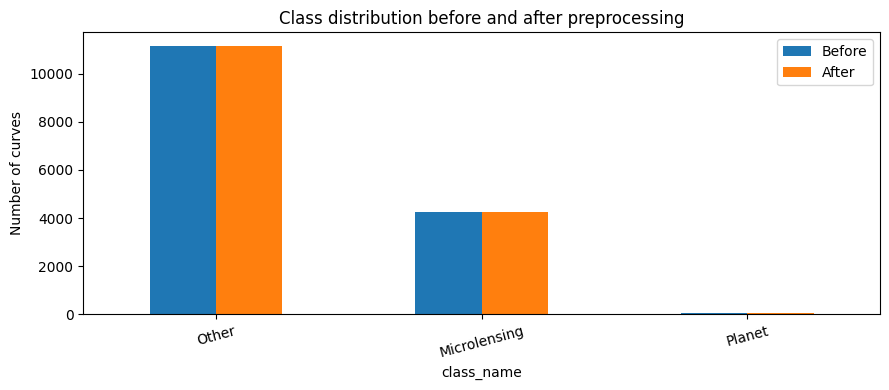

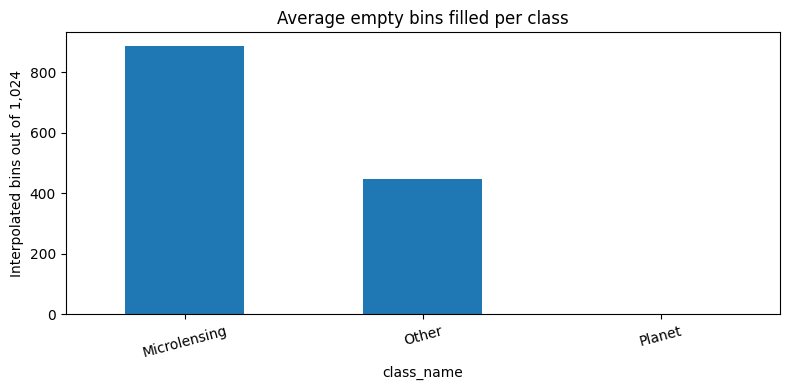

In [7]:
X_list, D_list, reports, kept = [], [], [], []

for i, row in metadata.iterrows():
    start, end = int(offsets[i]), int(offsets[i + 1])

    result = preprocess_curve(
        times[start:end],
        values[start:end],
        row['kind']
    )

    if result is None:
        continue

    X_curve, duration, info = result
    X_list.append(X_curve)
    D_list.append(duration)
    reports.append({
        'sample_id': row['sample_id'],
        'source': row['source'],
        'class_name': row['class_name'],
        'split': row['split'],
        **info
    })
    kept.append(i)

X = np.stack(X_list).astype(np.float32)
D = np.asarray(D_list, dtype=np.float32).reshape(-1, 1)

processed_meta = metadata.iloc[kept].reset_index(drop=True)
report = pd.DataFrame(reports)

y = processed_meta['label'].to_numpy(dtype=int)

print("Processed curves:", len(X))
print("Model input shape:", X.shape)
print("Duration feature shape:", D.shape)
print("Labels shape:", y.shape)

display(report.head())

# Visualise class balance before and after cleaning.
before = metadata['class_name'].value_counts()
after = processed_meta['class_name'].value_counts()

counts = pd.DataFrame({
    'Before': before,
    'After': after
}).fillna(0)

counts.plot(kind='bar', figsize=(9, 4))
plt.title('Class distribution before and after preprocessing')
plt.ylabel('Number of curves')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Visualise interpolated bins.
report.groupby('class_name')['empty_bins_interpolated'].mean().plot(
    kind='bar', figsize=(8, 4)
)
plt.title('Average empty bins filled per class')
plt.ylabel('Interpolated bins out of 1,024')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Before-and-after visualisations and heatmaps

Dataset shape: (15451, 1024, 2)
Labels found: [0 1 2]


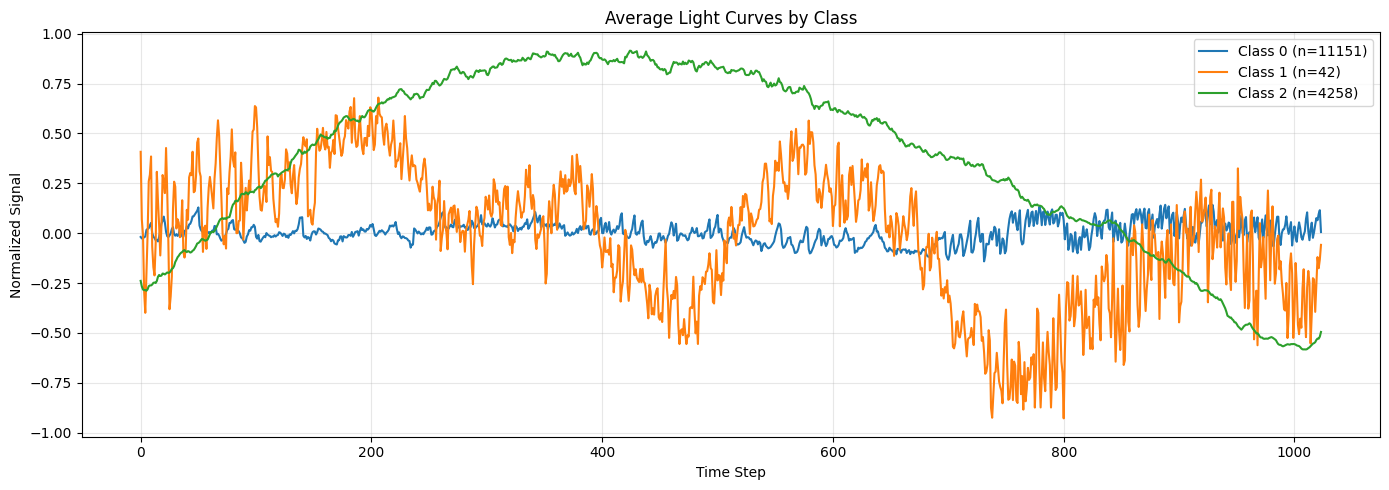

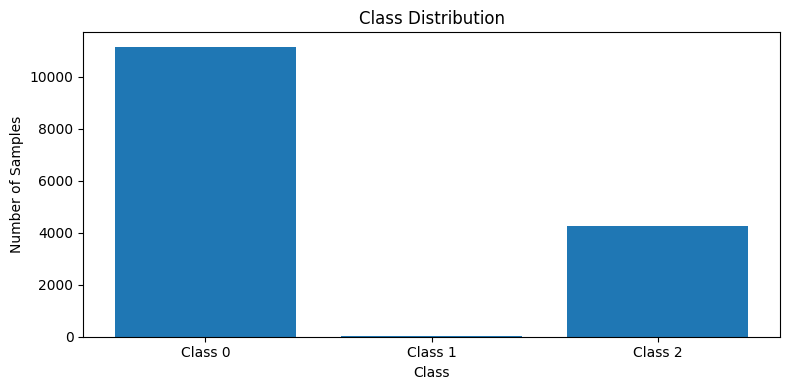

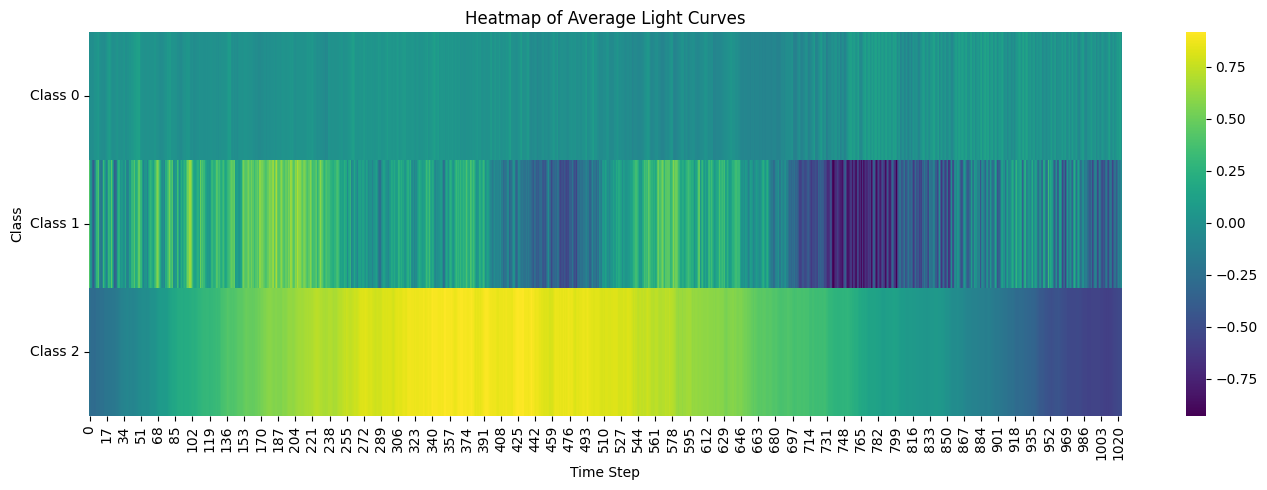

✅ All visualizations generated successfully!


In [11]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Check that the data exists
print("Dataset shape:", X.shape)
print("Labels found:", np.unique(y))

# Automatically handle ALL class labels
unique_labels = np.unique(y)

CLASS_NAMES = {
    label: f"Class {label}"
    for label in unique_labels
}

# -----------------------------------------
# 1. Before-and-after style: Average curves
# -----------------------------------------

plt.figure(figsize=(14, 5))

for label in unique_labels:
    mask = (y == label)

    if np.any(mask):
        # Average the first feature across samples
        average_curve = X[mask, :, 0].mean(axis=0)

        plt.plot(
            average_curve,
            label=f"{CLASS_NAMES[label]} (n={mask.sum()})"
        )

plt.title("Average Light Curves by Class")
plt.xlabel("Time Step")
plt.ylabel("Normalized Signal")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# -----------------------------------------
# 2. Class distribution
# -----------------------------------------

labels, counts = np.unique(y, return_counts=True)

plt.figure(figsize=(8, 4))
plt.bar(
    [CLASS_NAMES[label] for label in labels],
    counts
)

plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()


# -----------------------------------------
# 3. Heatmap of average curves
# -----------------------------------------

average_curves = []

for label in unique_labels:
    mask = (y == label)

    if np.any(mask):
        average_curves.append(X[mask, :, 0].mean(axis=0))

plt.figure(figsize=(14, 5))

sns.heatmap(
    np.array(average_curves),
    cmap="viridis"
)

plt.title("Heatmap of Average Light Curves")
plt.xlabel("Time Step")
plt.ylabel("Class")
plt.yticks(
    np.arange(len(unique_labels)) + 0.5,
    [CLASS_NAMES[label] for label in unique_labels],
    rotation=0
)

plt.tight_layout()
plt.show()

print("✅ All visualizations generated successfully!")